# Credit Scoring Model

## Objective

The objective of this project is to predict an individual's
creditworthiness using historical financial data.

Machine learning classification algorithms such as Logistic Regression,
Decision Tree, and Random Forest will be used.

In [11]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [12]:
import pandas as pd

# Location of the dataset
file_path = "../dataset/german.data"

# Load the dataset
data = pd.read_csv(file_path, sep=" ", header=None)

# Display first 5 rows
data.head()

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [13]:
# Give meaningful names to the columns

columns = [
    "checking_account",
    "duration",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings_account",
    "employment",
    "installment_rate",
    "personal_status_sex",
    "other_debtors",
    "present_residence",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "existing_credits",
    "job",
    "people_liable",
    "telephone",
    "foreign_worker",
    "credit_risk"
]

data.columns = columns

# Display the first 5 rows
data.head()

,checking_account,duration,credit_history,purpose,credit_amount,savings_account,employment,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [14]:
# Check the size of the dataset
print("Dataset Shape:", data.shape)

# Check data types
print("\nData Types:")
print(data.dtypes)

# Check for missing values
print("\nMissing Values:")
print(data.isnull().sum())

# Check the target column
print("\nCredit Risk Distribution:")
print(data["credit_risk"].value_counts())

Dataset Shape: (1000, 21)

Data Types:
checking_account             str
duration                   int64
credit_history               str
purpose                      str
credit_amount              int64
savings_account              str
employment                   str
installment_rate           int64
personal_status_sex          str
other_debtors                str
present_residence          int64
property                     str
age                        int64
other_installment_plans      str
housing                      str
existing_credits           int64
job                          str
people_liable              int64
telephone                    str
foreign_worker               str
credit_risk                int64
dtype: object

Missing Values:
checking_account           0
duration                   0
credit_history             0
purpose                    0
credit_amount              0
savings_account            0
employment                 0
installment_rate           0
perso

In [ ]:
# Convert credit risk into binary values
# 1 = Good credit → 1
# 2 = Bad credit  → 0

data["credit_risk"] = data["credit_risk"].map({
    1: 1,
    2: 0
})

# Check the result
print(data["credit_risk"].value_counts())


credit_risk
1    700
0    300
Name: count, dtype: int64


In [16]:
#display basic information about the dataset
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   checking_account         1000 non-null   str  
 1   duration                 1000 non-null   int64
 2   credit_history           1000 non-null   str  
 3   purpose                  1000 non-null   str  
 4   credit_amount            1000 non-null   int64
 5   savings_account          1000 non-null   str  
 6   employment               1000 non-null   str  
 7   installment_rate         1000 non-null   int64
 8   personal_status_sex      1000 non-null   str  
 9   other_debtors            1000 non-null   str  
 10  present_residence        1000 non-null   int64
 11  property                 1000 non-null   str  
 12  age                      1000 non-null   int64
 13  other_installment_plans  1000 non-null   str  
 14  housing                  1000 non-null   str  
 15  existing_credits

In [17]:
# in machine learning ,we divided our dataset into:
# x= input features =informmation used to make the prediction(customer financial information)
# y=target =what we want the model to predict (credit risk)

# Separate input features and target variable

X = data.drop("credit_risk", axis=1)
y = data["credit_risk"]

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (1000, 20)
Target (y) shape: (1000,)


In [18]:
#check the columns in x
print(x.column.toliist())

NameError: name 'x' is not defined

In [19]:
# Separate features (X) and target (y)

X = data.drop(columns=["credit_risk"])
y = data["credit_risk"]

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (1000, 20)
Target (y) shape: (1000,)


In [21]:
print(data.columns.tolist())

['checking_account', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings_account', 'employment', 'installment_rate', 'personal_status_sex', 'other_debtors', 'present_residence', 'property', 'age', 'other_installment_plans', 'housing', 'existing_credits', 'job', 'people_liable', 'telephone', 'foreign_worker', 'credit_risk']


In [22]:
columns = [
    "checking_account",
    "duration",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings_account",
    "employment",
    "installment_rate",
    "personal_status_sex",
    "other_debtors",
    "present_residence",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "existing_credits",
    "job",
    "people_liable",
    "telephone",
    "foreign_worker",
    "credit_risk"
]

data.columns = columns

# Separate features and target
X = data.drop(columns=["credit_risk"])
y = data["credit_risk"]

print("Total columns:", len(data.columns))
print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Total columns: 21
Features (X) shape: (1000, 20)
Target (y) shape: (1000,)


In [24]:
#check the data types of all features
print(X.dtypes)

checking_account             str
duration                   int64
credit_history               str
purpose                      str
credit_amount              int64
savings_account              str
employment                   str
installment_rate           int64
personal_status_sex          str
other_debtors                str
present_residence          int64
property                     str
age                        int64
other_installment_plans      str
housing                      str
existing_credits           int64
job                          str
people_liable              int64
telephone                    str
foreign_worker               str
dtype: object


In [25]:
# Convert categorical columns into numerical columns

X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

print("Original X shape:", X.shape)
print("Encoded X shape:", X_encoded.shape)

# Display first 5 rows
X_encoded.head()

Original X shape: (1000, 20)
Encoded X shape: (1000, 48)


,duration,credit_amount,installment_rate,present_residence,age,existing_credits,people_liable,checking_account_A12,checking_account_A13,checking_account_A14,...,property_A124,other_installment_plans_A142,other_installment_plans_A143,housing_A152,housing_A153,job_A172,job_A173,job_A174,telephone_A192,foreign_worker_A202
0,6,1169,4,4,67,2,1,0,0,0,...,0,0,1,1,0,0,1,0,1,0
1,48,5951,2,2,22,1,1,1,0,0,...,0,0,1,1,0,0,1,0,0,0
2,12,2096,2,3,49,1,2,0,0,1,...,0,0,1,1,0,1,0,0,0,0
3,42,7882,2,4,45,1,2,0,0,0,...,0,0,1,0,1,0,1,0,0,0
4,24,4870,3,4,53,2,2,0,0,0,...,1,0,1,0,1,0,1,0,0,0


In [26]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (800, 48)
X_test: (200, 48)
y_train: (800,)
y_test: (200,)


In [ ]:
#feature scaling
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Scale training data
X_train_scaled = scaler.fit_transform(X_train)

# Scale testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Scaled X_train shape:", X_train_scaled.shape)
print("Scaled X_test shape:", X_test_scaled.shape)

Scaled X_train shape: (800, 48)
Scaled X_test shape: (200, 48)


In [28]:
#train logistic regression
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
logistic_model = LogisticRegression(random_state=42, max_iter=1000)

# Train the model
logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [29]:
#make prediction
# Make predictions on the test data

y_pred = logistic_model.predict(X_test_scaled)

print("Predictions made successfully!")
print("First 10 predictions:", y_pred[:10])

Predictions made successfully!
First 10 predictions: [1 0 0 1 0 1 1 1 0 1]


In [30]:
#evaluate lagostic regression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Get probability of Good Credit
y_probability = logistic_model.predict_proba(X_test_scaled)[:, 1]

roc_auc = roc_auc_score(y_test, y_probability)

print("Logistic Regression Performance")
print("--------------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

Logistic Regression Performance
--------------------------------
Accuracy : 0.71
Precision: 0.7808
Recall   : 0.8143
F1-Score : 0.7972
ROC-AUC  : 0.7531


In [1]:
#confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Display confusion matrix as a heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Bad Credit", "Good Credit"],
    yticklabels=["Bad Credit", "Good Credit"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

NameError: name 'y_test' is not defined

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

NameError: name 'X_encoded' is not defined

In [3]:
# Convert categorical columns into numerical columns

X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

print("Original X shape:", X.shape)
print("Encoded X shape:", X_encoded.shape)

NameError: name 'pd' is not defined

In [4]:
# Import Pandas
import pandas as pd

# Load the German Credit dataset
file_path = "../dataset/german.data"

data = pd.read_csv(
    file_path,
    sep=r"\s+",
    header=None
)

# Add column names
columns = [
    "checking_account",
    "duration",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings_account",
    "employment",
    "installment_rate",
    "personal_status_sex",
    "other_debtors",
    "present_residence",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "existing_credits",
    "job",
    "people_liable",
    "telephone",
    "foreign_worker",
    "credit_risk"
]

data.columns = columns

# Convert target:
# 1 = Good Credit
# 2 = Bad Credit
data["credit_risk"] = data["credit_risk"].map({
    1: 1,
    2: 0
})

# Separate features and target
X = data.drop(columns=["credit_risk"])
y = data["credit_risk"]

# Convert categorical features into numerical features
X_encoded = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

print("Dataset shape:", data.shape)
print("Original X shape:", X.shape)
print("Encoded X shape:", X_encoded.shape)
print("Target shape:", y.shape)

Dataset shape: (1000, 21)
Original X shape: (1000, 20)
Encoded X shape: (1000, 48)
Target shape: (1000,)


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (800, 48)
X_test: (200, 48)
y_train: (800,)
y_test: (200,)


In [6]:
#features scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled X_train:", X_train_scaled.shape)
print("Scaled X_test:", X_test_scaled.shape)

Scaled X_train: (800, 48)
Scaled X_test: (200, 48)


In [7]:
#train logistic regression
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [8]:
#make prediction using logistic regression
# Make predictions using Logistic Regression

y_pred = logistic_model.predict(X_test_scaled)

print("Predictions made successfully!")
print("First 10 predictions:", y_pred[:10])

Predictions made successfully!
First 10 predictions: [1 0 0 1 0 1 1 1 0 1]


In [9]:
#evaluate the model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Probability for ROC-AUC
y_probability = logistic_model.predict_proba(X_test_scaled)[:, 1]

roc_auc = roc_auc_score(y_test, y_probability)

print("Logistic Regression Performance")
print("--------------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

Logistic Regression Performance
--------------------------------
Accuracy : 0.71
Precision: 0.7808
Recall   : 0.8143
F1-Score : 0.7972
ROC-AUC  : 0.7531


In [10]:
#take decision tree 
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    random_state=42
)

decision_tree.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [11]:
#predictions using decision tree
y_pred_dt = decision_tree.predict(X_test)

print("First 10 predictions:")
print(y_pred_dt[:10])

First 10 predictions:
[1 0 1 1 0 1 1 0 1 1]


In [12]:
#evaluate decision tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)

y_prob_dt = decision_tree.predict_proba(X_test)[:,1]
roc_auc_dt = roc_auc_score(y_test, y_prob_dt)

print("Decision Tree Performance")
print("-------------------------")
print("Accuracy :", round(accuracy_dt,4))
print("Precision:", round(precision_dt,4))
print("Recall   :", round(recall_dt,4))
print("F1-Score :", round(f1_dt,4))
print("ROC-AUC  :", round(roc_auc_dt,4))

Decision Tree Performance
-------------------------
Accuracy : 0.715
Precision: 0.8029
Recall   : 0.7857
F1-Score : 0.7942
ROC-AUC  : 0.6679


In [13]:
#train random forest
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [14]:
#prediction
y_pred_rf = random_forest.predict(X_test)

In [16]:
#evaluate the random forest
# Evaluate Random Forest

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

# Probability for ROC-AUC
y_prob_rf = random_forest.predict_proba(X_test)[:, 1]
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Performance")
print("-------------------------")
print("Accuracy :", round(accuracy_rf, 4))
print("Precision:", round(precision_rf, 4))
print("Recall   :", round(recall_rf, 4))
print("F1-Score :", round(f1_rf, 4))
print("ROC-AUC  :", round(roc_auc_rf, 4))

Random Forest Performance
-------------------------
Accuracy : 0.735
Precision: 0.7736
Recall   : 0.8786
F1-Score : 0.8227
ROC-AUC  : 0.7774


In [17]:
#compared all three machine learning  model
# Compare all three machine learning models

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        accuracy_dt,
        accuracy_rf
    ],
    "Precision": [
        precision,
        precision_dt,
        precision_rf
    ],
    "Recall": [
        recall,
        recall_dt,
        recall_rf
    ],
    "F1-Score": [
        f1,
        f1_dt,
        f1_rf
    ],
    "ROC-AUC": [
        roc_auc,
        roc_auc_dt,
        roc_auc_rf
    ]
})

comparison.round(4)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.710,0.7808,0.8143,0.7972,0.7531
1,Decision Tree,0.715,0.8029,0.7857,0.7942,0.6679
2,Random Forest,0.735,0.7736,0.8786,0.8227,0.7774


In [18]:
#find and select best model 
# Find the best model based on F1-Score

best_model_name = comparison.loc[
    comparison["F1-Score"].idxmax(), "Model"
]

best_f1_score = comparison["F1-Score"].max()

print("Best Model:", best_model_name)
print("Best F1-Score:", round(best_f1_score, 4))

Best Model: Random Forest
Best F1-Score: 0.8227


In [19]:
#save the best model
import joblib
import os

# Select the best model
if best_model_name == "Logistic Regression":
    best_model = logistic_model

elif best_model_name == "Decision Tree":
    best_model = decision_tree

elif best_model_name == "Random Forest":
    best_model = random_forest

# Create model folder if it doesn't exist
os.makedirs("../model", exist_ok=True)

# Save the best model
joblib.dump(best_model, "../model/best_credit_model.pkl")

# Save the scaler
joblib.dump(scaler, "../model/scaler.pkl")

# Save the feature names used by the model
joblib.dump(X_encoded.columns.tolist(), "../model/feature_columns.pkl")

print("Best model saved successfully!")
print("Model:", best_model_name)
print("Location: model/best_credit_model.pkl")

Best model saved successfully!
Model: Random Forest
Location: model/best_credit_model.pkl


In [20]:
#load the saved model and test it
import joblib

# Load the saved model
loaded_model = joblib.load("../model/best_credit_model.pkl")

# Load the scaler
loaded_scaler = joblib.load("../model/scaler.pkl")

# Load the feature columns
feature_columns = joblib.load("../model/feature_columns.pkl")

print("Saved model loaded successfully!")
print("Number of features:", len(feature_columns))

Saved model loaded successfully!
Number of features: 48


In [21]:
#create a new customer
# Example new customer

new_customer = pd.DataFrame([{
    "checking_account": "A12",
    "duration": 24,
    "credit_history": "A32",
    "purpose": "A43",
    "credit_amount": 5000,
    "savings_account": "A61",
    "employment": "A73",
    "installment_rate": 3,
    "personal_status_sex": "A93",
    "other_debtors": "A101",
    "present_residence": 2,
    "property": "A121",
    "age": 30,
    "other_installment_plans": "A143",
    "housing": "A152",
    "existing_credits": 1,
    "job": "A173",
    "people_liable": 1,
    "telephone": "A192",
    "foreign_worker": "A201"
}])

print("New customer created successfully!")
print(new_customer)

New customer created successfully!
  checking_account  duration credit_history purpose  credit_amount  \
0              A12        24            A32     A43           5000   

  savings_account employment  installment_rate personal_status_sex  \
0             A61        A73                 3                 A93   

  other_debtors  present_residence property  age other_installment_plans  \
0          A101                  2     A121   30                    A143   

  housing  existing_credits   job  people_liable telephone foreign_worker  
0    A152                 1  A173              1      A192           A201  


In [22]:
#convert the new customer categorial data into model ready data
# Convert new customer categorical data into encoded features

new_customer_encoded = pd.get_dummies(
    new_customer,
    drop_first=True,
    dtype=int
)

# Make sure the columns are exactly the same as during model training
new_customer_encoded = new_customer_encoded.reindex(
    columns=feature_columns,
    fill_value=0
)

print("Encoded customer shape:", new_customer_encoded.shape)


Encoded customer shape: (1, 48)


In [23]:
#make a prdiction for the new customer
# Scale the encoded customer data
new_customer_scaled = loaded_scaler.transform(new_customer_encoded)

# Make prediction
prediction = loaded_model.predict(new_customer_scaled)[0]

# Get prediction probabilities
probability = loaded_model.predict_proba(new_customer_scaled)[0]

print("Prediction completed successfully!")
print("Prediction:", prediction)
print("Probability of Bad Credit:", round(probability[0], 4))
print("Probability of Good Credit:", round(probability[1], 4))

Prediction completed successfully!
Prediction: 1
Probability of Bad Credit: 0.34
Probability of Good Credit: 0.66


c:\Users\kalyani\OneDrive\Desktop\credit_scoring_model\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\kalyani\OneDrive\Desktop\credit_scoring_model\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [24]:
#display a professional final result
if prediction == 1:
    credit_result = "GOOD CREDIT"
else:
    credit_result = "BAD CREDIT"

print("====================================")
print("       CREDIT SCORING RESULT")
print("====================================")
print("Customer Credit Status:", credit_result)
print("Good Credit Probability:", round(probability[1] * 100, 2), "%")
print("Bad Credit Probability :", round(probability[0] * 100, 2), "%")
print("====================================")

       CREDIT SCORING RESULT
Customer Credit Status: GOOD CREDIT
Good Credit Probability: 66.0 %
Bad Credit Probability : 34.0 %


Confusion Matrix:
[[ 28  32]
 [ 26 114]]


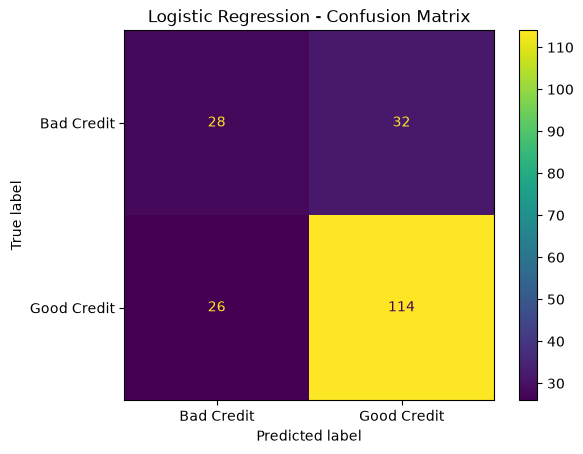

In [25]:
#create confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Bad Credit", "Good Credit"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

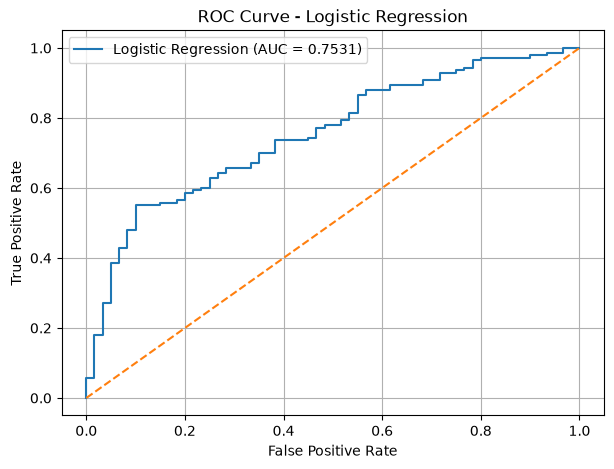

ROC-AUC Score: 0.7531


In [26]:
#create ROC curve
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get probability of Good Credit
y_prob = logistic_model.predict_proba(X_test_scaled)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate ROC-AUC
auc_score = roc_auc_score(y_test, y_prob)

# Plot ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", round(auc_score, 4))

Top 10 Important Features:
                         Feature  Importance
1                  credit_amount    0.117711
0                       duration    0.094225
4                            age    0.089851
9           checking_account_A14    0.070370
3              present_residence    0.039370
2               installment_rate    0.039077
13            credit_history_A34    0.023731
40  other_installment_plans_A143    0.023698
46                telephone_A192    0.021224
36                 property_A122    0.019886


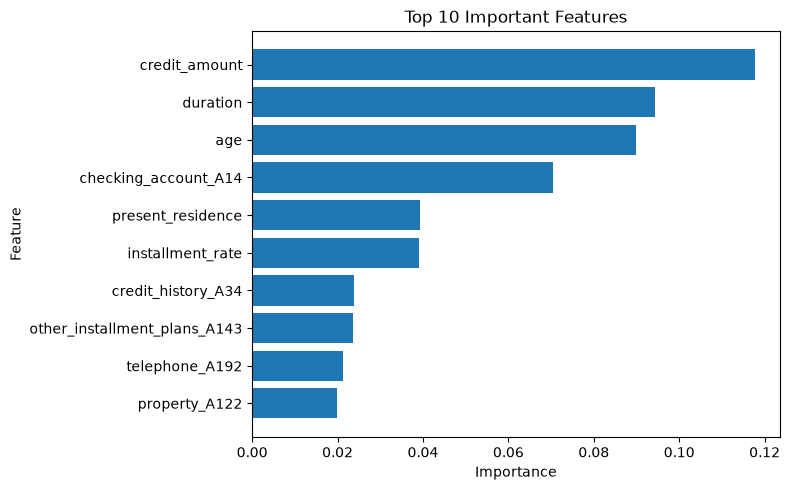

In [27]:
# features importance
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance
if best_model_name == "Logistic Regression":
    importance = abs(best_model.coef_[0])

elif best_model_name in ["Decision Tree", "Random Forest"]:
    importance = best_model.feature_importances_

# Create feature importance table
feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": importance
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Important Features:")
print(feature_importance.head(10))

# Plot top 10 features
top_features = feature_importance.head(10).sort_values("Importance")

plt.figure(figsize=(8, 5))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Important Features")
plt.tight_layout()
plt.show()

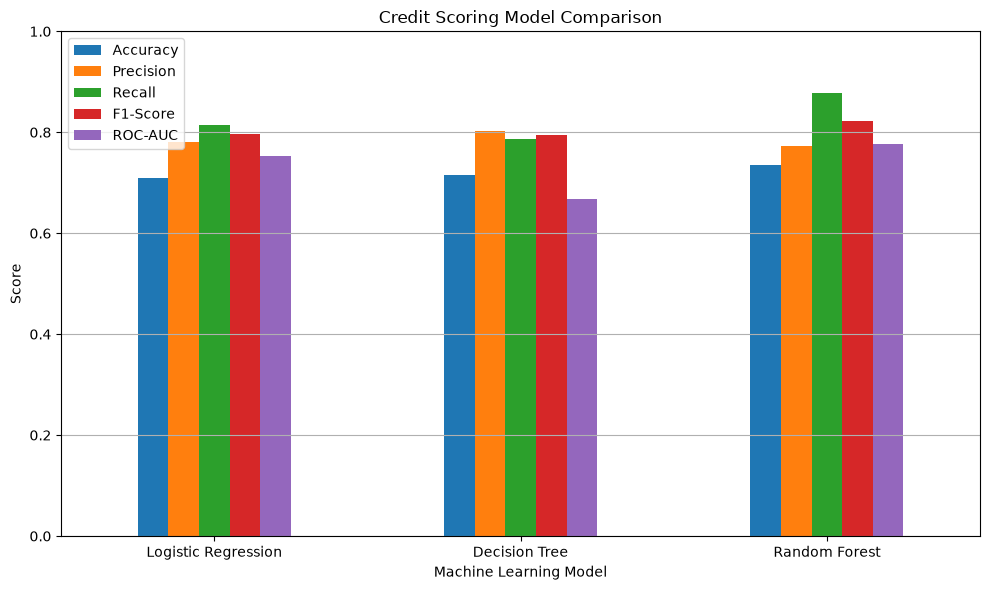

Model comparison graph saved successfully!
Location: graphs/model_comparison.png


In [28]:
#save model comparison graph
import matplotlib.pyplot as plt
import os

# Create graphs folder if it doesn't exist
os.makedirs("../graphs", exist_ok=True)

# Plot model comparison
comparison.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Credit Scoring Model Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y")
plt.tight_layout()

# Save graph
plt.savefig("../graphs/model_comparison.png", dpi=300)

plt.show()

print("Model comparison graph saved successfully!")
print("Location: graphs/model_comparison.png")

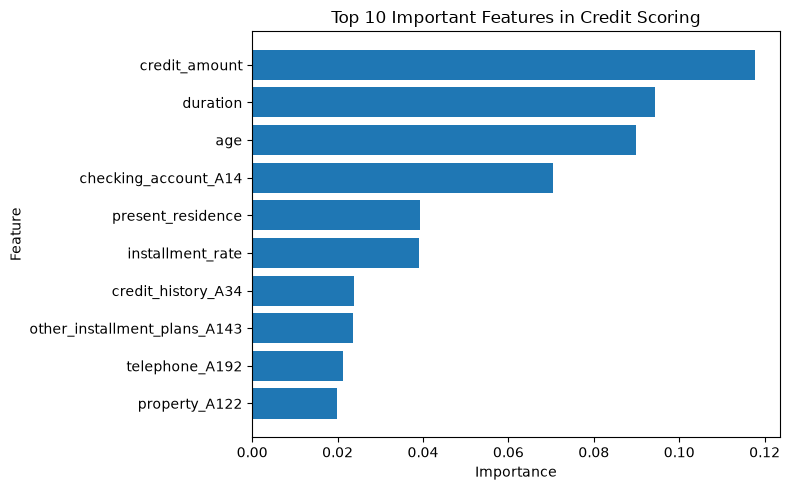

Feature importance graph saved successfully!
Location: graphs/feature_importance.png


In [29]:
#save the features importance graph
import matplotlib.pyplot as plt
import os

# Create graphs folder
os.makedirs("../graphs", exist_ok=True)

# Get top 10 features
top_features = feature_importance.head(10).sort_values("Importance")

# Create graph
plt.figure(figsize=(8, 5))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Important Features in Credit Scoring")

plt.tight_layout()

# Save graph
plt.savefig("../graphs/feature_importance.png", dpi=300)

plt.show()

print("Feature importance graph saved successfully!")
print("Location: graphs/feature_importance.png")

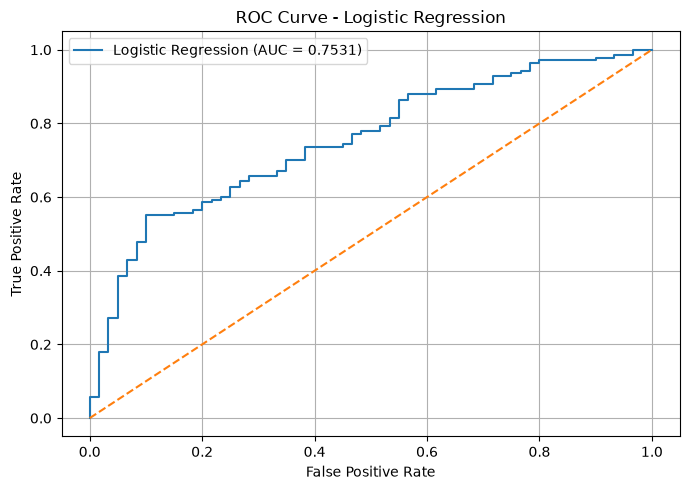

ROC Curve saved successfully!
Location: graphs/roc_curve.png


In [30]:
#saved the ROC curve
import matplotlib.pyplot as plt
import os

# Create graphs folder if needed
os.makedirs("../graphs", exist_ok=True)

# ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc_score:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid()

plt.tight_layout()

# Save ROC curve
plt.savefig("../graphs/roc_curve.png", dpi=300)

plt.show()

print("ROC Curve saved successfully!")
print("Location: graphs/roc_curve.png")

In [31]:
#create final model result table
# Create final results table

final_results = comparison.copy()

# Round the scores to 4 decimal places
final_results[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
] = final_results[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
].round(4)

print("FINAL MODEL PERFORMANCE")
print("=======================")
print(final_results.to_string(index=False))

FINAL MODEL PERFORMANCE
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression     0.710     0.7808  0.8143    0.7972   0.7531
      Decision Tree     0.715     0.8029  0.7857    0.7942   0.6679
      Random Forest     0.735     0.7736  0.8786    0.8227   0.7774


In [32]:
#saved this table
final_results.to_csv("../graphs/final_model_results.csv", index=False)

print("Final results saved successfully!")
print("Location: graphs/final_model_results.csv")

Final results saved successfully!
Location: graphs/final_model_results.csv
